In [12]:
pip install numpy opencv-python scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [13]:
import numpy as np
import cv2
import os
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt


In [14]:
import os
import cv2
import numpy as np

def load_images_from_folder(folder):
    images = []
    labels = []
    label_map = {}  # Map directory names to labels
    label_counter = 0
    
    for subfolder in os.listdir(folder):
        subfolder_path = os.path.join(folder, subfolder)
        if os.path.isdir(subfolder_path):
            label_map[subfolder] = label_counter
            label_counter += 1
            for filename in os.listdir(subfolder_path):
                file_path = os.path.join(subfolder_path, filename)
                img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    img = cv2.resize(img, (64, 64))
                    images.append(img.flatten())
                    labels.append(label_map[subfolder])
    
    return np.array(images), np.array(labels)

# Load the data
X, y = load_images_from_folder('C:\\Users\\Sed_eeeem\\Desktop\\Sedeeeem\\Second Semester\\Data Science\\Project\\Dataset')

# Check the unique labels
print("Unique labels in y:", np.unique(y))


print(f'Number of images loaded: {X.shape[0]}')
print(f'Number of labels loaded: {y.shape[0]}')
print(f'Image dimensions: {X.shape[1:]}')  # Should be (64*64,) if flattened





Unique labels in y: [0 1 2]
Number of images loaded: 147
Number of labels loaded: 147
Image dimensions: (4096,)


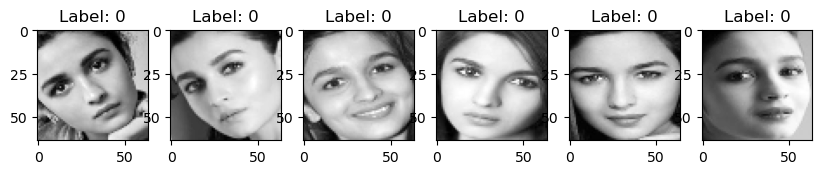

(147,)

In [15]:
#Display some of the images.
import matplotlib.pyplot as plt

def display_sample_images(images, labels, num_samples=6):
    plt.figure(figsize=(10, 5))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(images[i].reshape(64, 64), cmap='gray')
        plt.title(f'Label: {labels[i]}')
        plt.axis('off')
    plt.show()

display_sample_images( X,y)
y.shape


In [16]:
# Print first few labels and images
print("First few labels:", y[10:])
print("First few images shape:", X[:10].shape)


First few labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
First few images shape: (10, 4096)


In [17]:
print("Number of samples in X:", len(X))
print("Number of samples in y:", len(y))

# Check first few samples
print("First few samples of X:", X[:5])
print("First few labels of y:", y[:5])



Number of samples in X: 147
Number of samples in y: 147
First few samples of X: [[ 47  65  44 ...  55  31  18]
 [ 26  29  26 ... 155 164 179]
 [ 67  42  20 ...  27  29  40]
 [150 145 126 ...  50  40  37]
 [  5   9  10 ... 179 167 148]]
First few labels of y: [0 0 0 0 0]


In [18]:
# Check data shapes before splitting
print("Before splitting:")
print("X shape:", X.shape)
print("y shape:", y.shape)


Before splitting:
X shape: (147, 4096)
y shape: (147,)


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

# Check data shapes after splitting
print("After splitting:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

After splitting:
X_train shape: (73, 4096)
X_test shape: (74, 4096)
y_train shape: (73,)
y_test shape: (74,)


In [20]:
classifier = DecisionTreeClassifier(random_state=42)
classifier.fit(X_train, y_train)


DecisionTreeClassifier(random_state=42)

In [21]:
# Predict on the test set
y_pred = classifier.predict(X_test)

In [22]:
# Check lengths
print("Length of y_test:", len(y_test))
print("Length of y_pred:", len(y_pred))


Length of y_test: 74
Length of y_pred: 74


In [23]:
pip install seaborn matplotlib


Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)


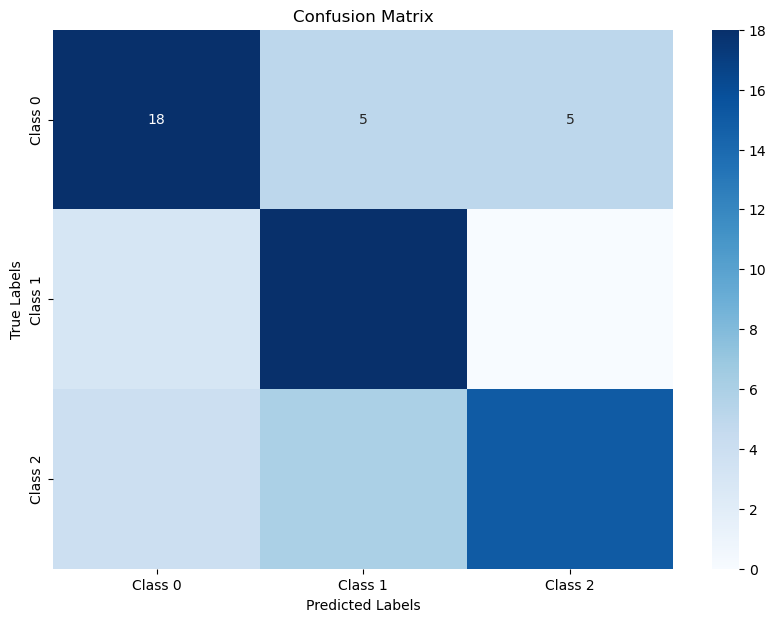

In [25]:
plt.figure(figsize=(10, 7))  # Adjust the size as needed
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True, 
            xticklabels=['Class 0', 'Class 1', 'Class 2'],  # Replace with your class names
            yticklabels=['Class 0', 'Class 1', 'Class 2'])  # Replace with your class names
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


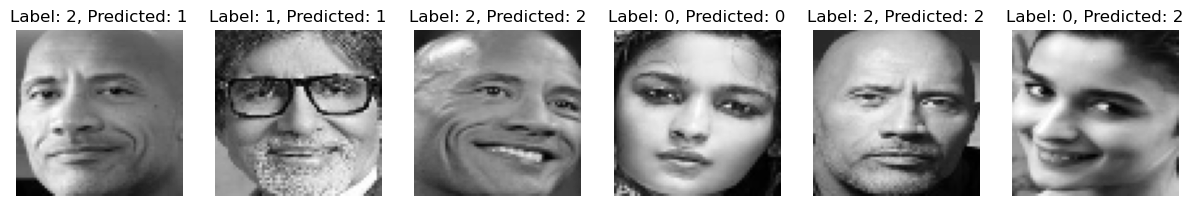

In [26]:
def plot_images(images, labels, predictions, n=6):
    plt.figure(figsize=(15, 5))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[i].reshape(64, 64), cmap='gray')
        plt.title(f'Label: {labels[i]}, Predicted: {predictions[i]}')
        plt.axis('off')
    plt.show()

plot_images(X_test, y_test, y_pred)


In [27]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


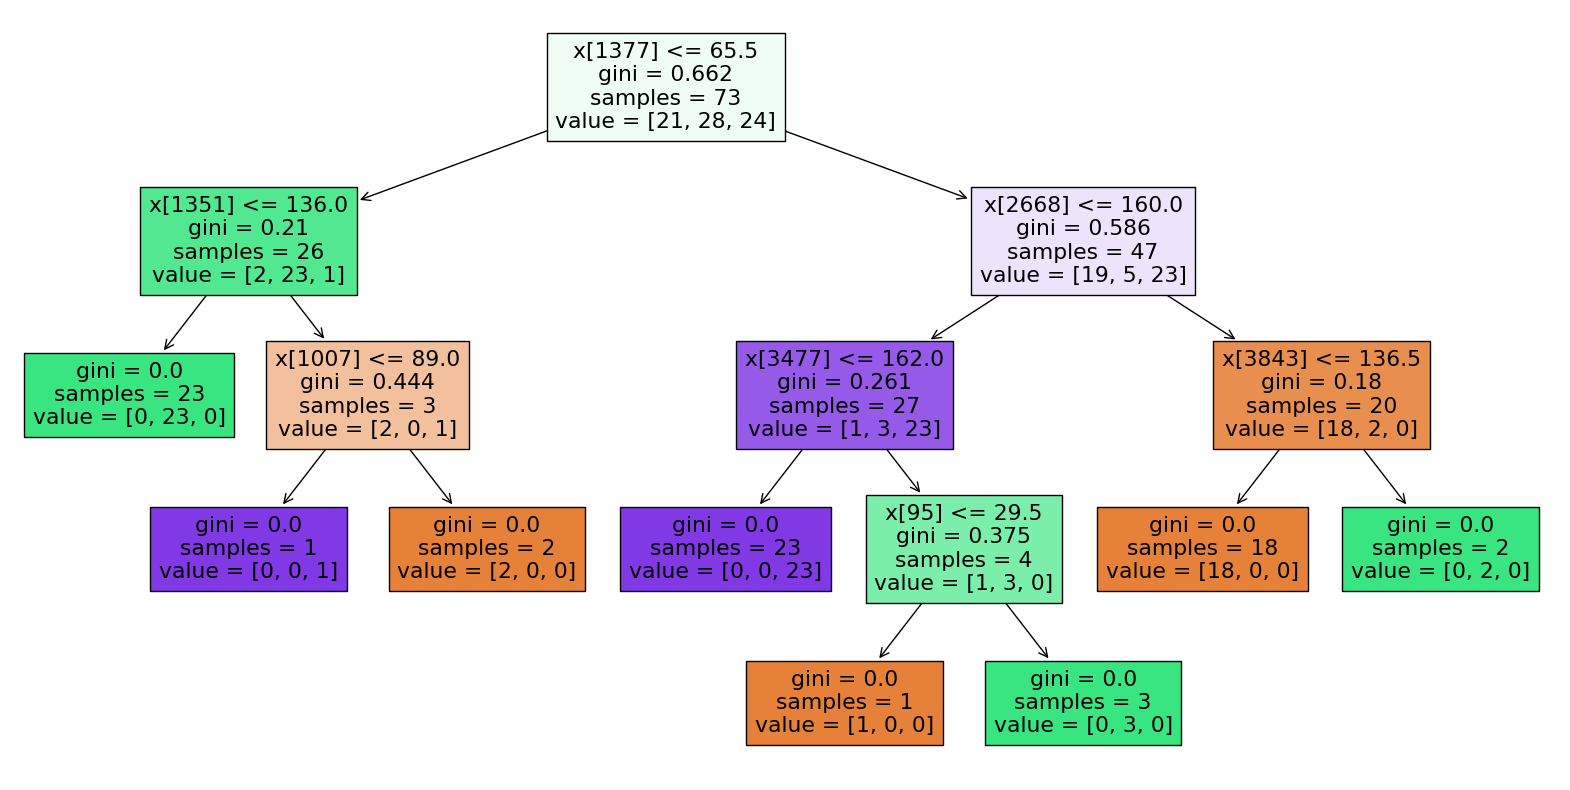

In [28]:
# Assuming classifier is your trained DecisionTreeClassifier
plt.figure(figsize=(20, 10))
plot_tree(classifier, filled=True, feature_names=None, class_names=None)
plt.show()


In [29]:
# Evaluate
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Accuracy:", accuracy)


Accuracy: 0.6891891891891891
